In [2]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Python executable:", sys.executable)
print("Dataset available:", (PROJECT_ROOT / "data/splits/train_final.csv").exists())
print("Evaluation available:", (PROJECT_ROOT / "results/evaluation/comparison.csv").exists())

Project root: /home/nmafi/applied-ai-midterm
Python executable: /home/nmafi/applied-ai-midterm/.venv/bin/python
Dataset available: True
Evaluation available: True


In [3]:
# Load dataset split information

split_files = {
    "Training": "train_final.csv",
    "Validation": "val.csv",
    "Testing": "test.csv"
}

split_counts = {}

for split_name, filename in split_files.items():
    df = pd.read_csv(PROJECT_ROOT / "data/splits" / filename)
    split_counts[split_name] = len(df)

split_df = pd.DataFrame(
    list(split_counts.items()),
    columns=["Dataset Split", "Number of Images"]
)

display(split_df)

total = sum(split_counts.values())

print(f"Total images: {total:,}")
print(f"Training + Validation: {(split_counts['Training'] + split_counts['Validation']) / total * 100:.1f}%")
print(f"Testing: {split_counts['Testing'] / total * 100:.1f}%")

,Dataset Split,Number of Images
0,Training,15750
1,Validation,1750
2,Testing,7500


Total images: 25,000
Training + Validation: 70.0%
Testing: 30.0%


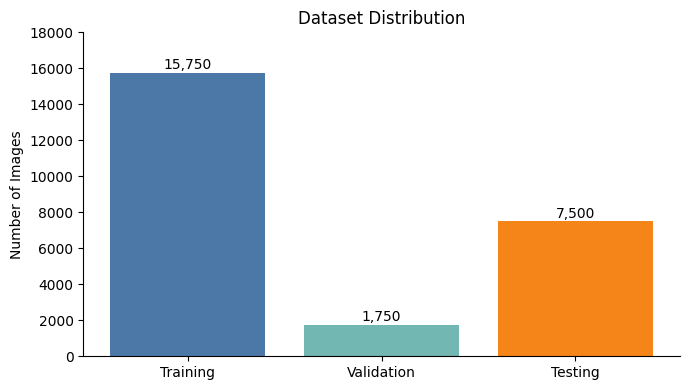

In [4]:
# visualization 
fig, ax = plt.subplots(figsize=(7, 4))

colors = ["#4C78A8", "#72B7B2", "#F58518"]

bars = ax.bar(
    split_df["Dataset Split"],
    split_df["Number of Images"],
    color=colors
)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 200,
        f"{int(height):,}",
        ha="center"
    )

ax.set_ylabel("Number of Images")
ax.set_title("Dataset Distribution")
ax.set_ylim(0, 18000)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## Image Preprocessing and Super-Resolution

The original images are resized to 128 × 128 pixels. Low-resolution
images are created by downsampling them to 32 × 32 pixels.

The trained SRGAN generator reconstructs 128 × 128 images from these
low-resolution inputs. The examples below compare the original images,
low-resolution inputs, and SRGAN outputs.

In [5]:
from PIL import Image
import matplotlib.pyplot as plt

# Inspect the original and SRGAN-generated dataset records
original_df = pd.read_csv(PROJECT_ROOT / "data/splits/test.csv")
srgan_df = pd.read_csv(PROJECT_ROOT / "data/splits/test_srgan.csv")

print("Original dataset columns:", original_df.columns.tolist())
print("SRGAN dataset columns:", srgan_df.columns.tolist())

display(original_df.head(3))
display(srgan_df.head(3))


Original dataset columns: ['filepath', 'label']
SRGAN dataset columns: ['filepath', 'label']


,filepath,label
0,data/raw/train/train/dog.12468.jpg,1
1,data/raw/train/train/dog.1986.jpg,1
2,data/raw/train/train/dog.2661.jpg,1


,filepath,label
0,data/srgan_enhanced/test/dog.12468.png,1
1,data/srgan_enhanced/test/dog.1986.png,1
2,data/srgan_enhanced/test/dog.2661.png,1


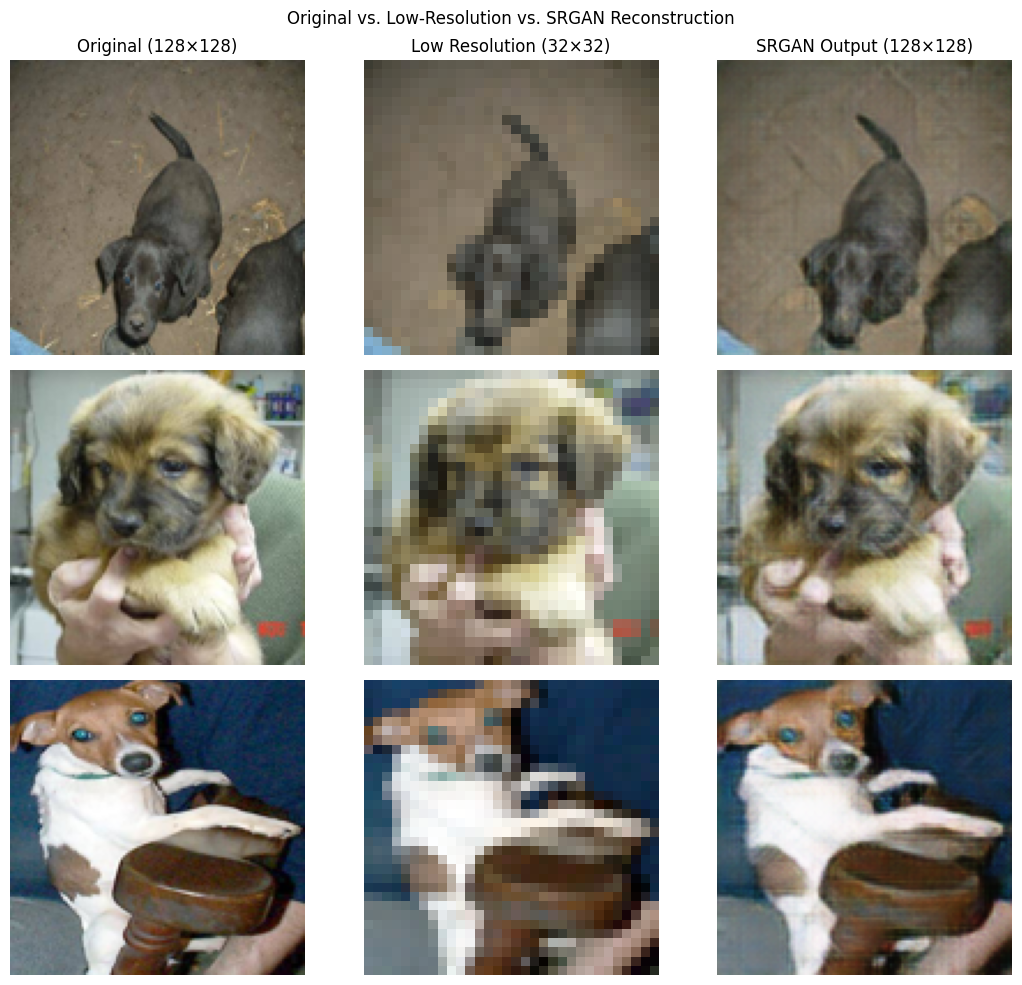

In [6]:
# comparing original, low resolution, and SRGAN images
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Select three corresponding test samples
sample_indices = [0, 1, 2]

fig, axes = plt.subplots(3, 3, figsize=(11, 10))

for row, idx in enumerate(sample_indices):
    original_path = PROJECT_ROOT / original_df.iloc[idx]["filepath"]
    srgan_path = PROJECT_ROOT / srgan_df.iloc[idx]["filepath"]

    # Original image resized to 128x128
    with Image.open(original_path) as img:
        original = img.convert("RGB").resize(
            (128, 128), Image.Resampling.BICUBIC
        )

    # Low-resolution input (32x32)
    low_res = original.resize(
        (32, 32), Image.Resampling.BICUBIC
    )

    # Generated SRGAN image (128x128)
    with Image.open(srgan_path) as img:
        srgan = img.convert("RGB").resize((128, 128))

    axes[row, 0].imshow(original)
    axes[row, 1].imshow(low_res)
    axes[row, 2].imshow(srgan)

    for col in range(3):
        axes[row, col].axis("off")

axes[0, 0].set_title("Original (128×128)")
axes[0, 1].set_title("Low Resolution (32×32)")
axes[0, 2].set_title("SRGAN Output (128×128)")

plt.suptitle("Original vs. Low-Resolution vs. SRGAN Reconstruction")
plt.tight_layout()
plt.show()


## SRGAN Training and Evaluation

The SRGAN generator was trained using low-resolution 32 × 32 images
and corresponding 128 × 128 reference images.

The adversarial training ran for 150 epochs. we evaluate
reconstruction quality using Peak Signal-to-Noise Ratio (PSNR) and Structural Similarity Index (SSIM).

Number of training epochs: 150


,epoch,g_loss,d_loss,pixel_loss,perceptual_loss,adversarial_loss,val_mse,val_psnr,val_ssim
147,148,0.116893,1.340560e-15,0.014249,17.087391,0.119406,0.015017,24.996595,0.699684
148,149,0.117748,1.052192e-14,0.014257,17.226717,0.130954,0.014304,25.268063,0.700432
149,150,0.116534,6.514916e-13,0.014246,17.028658,0.116391,0.014121,25.309795,0.703314


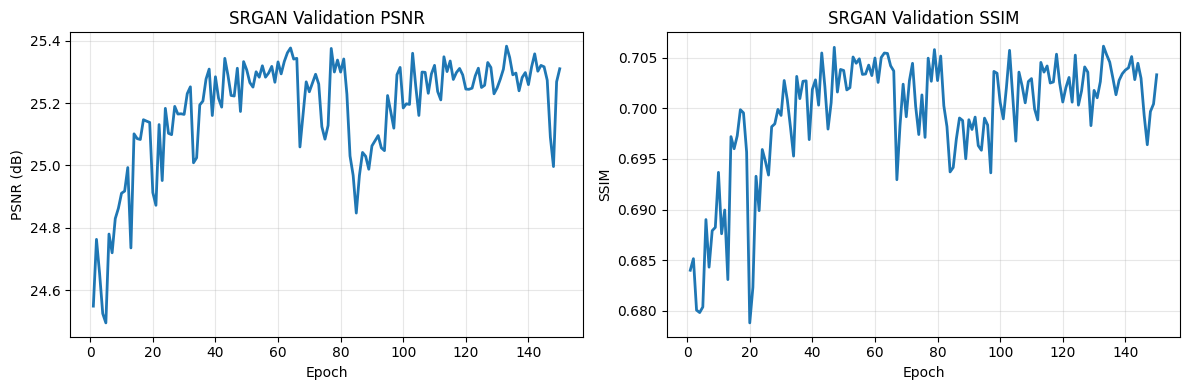

In [7]:
# Load the saved SRGAN training history
srgan_history = pd.read_csv(
    PROJECT_ROOT / "results/srgan/gan_history.csv"
)

print("Number of training epochs:", len(srgan_history))
display(srgan_history.tail(3))

# Plot validation PSNR and SSIM
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

epochs = srgan_history["epoch"]

axes[0].plot(
    epochs,
    srgan_history["val_psnr"],
    linewidth=2
)
axes[0].set_title("SRGAN Validation PSNR")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("PSNR (dB)")
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs,
    srgan_history["val_ssim"],
    linewidth=2
)
axes[1].set_title("SRGAN Validation SSIM")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("SSIM")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Model A and Model B Training Performance

Model A uses transfer learning with MobileNetV2 to classify the original
128 × 128 images.

Model B uses the same backbone architecture but is trained on
128 × 128 images reconstructed by SRGAN.

Both models were trained in stages, including classifier-head training,
continued training, and fine-tuning. The plots below show validation
accuracy and loss across these stages.


Model A training epochs: 32
Model B training epochs: 34


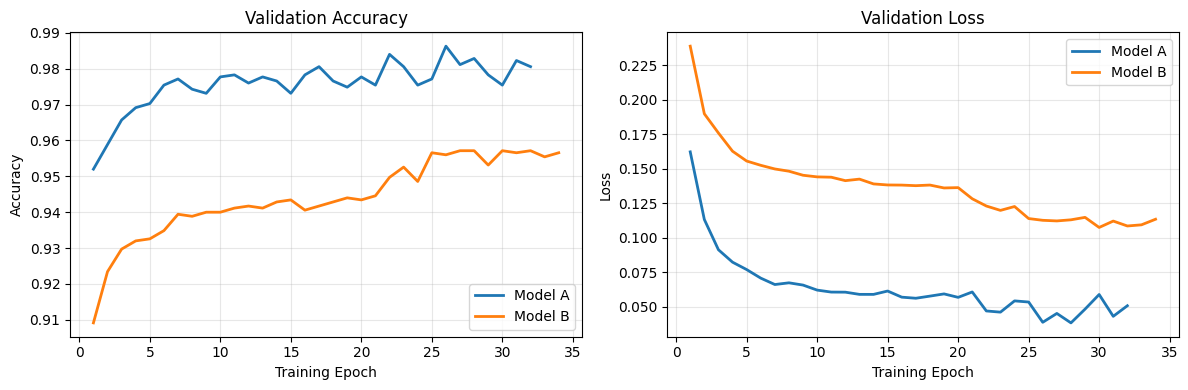

In [8]:
def load_classifier_history(model_name):
    folder = PROJECT_ROOT / "results" / model_name

    files = [
        "head_history.csv",
        "head_continued_history.csv",
        "finetune_history.csv",
    ]

    histories = []

    for filename in files:
        df = pd.read_csv(folder / filename)
        df["stage"] = filename.replace("_history.csv", "")
        histories.append(df)

    history = pd.concat(histories, ignore_index=True)
    history["training_epoch"] = np.arange(1, len(history) + 1)

    return history


history_a = load_classifier_history("model_a")
history_b = load_classifier_history("model_b")

print("Model A training epochs:", len(history_a))
print("Model B training epochs:", len(history_b))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_a["training_epoch"],
    history_a["val_accuracy"],
    label="Model A",
    linewidth=2
)

axes[0].plot(
    history_b["training_epoch"],
    history_b["val_accuracy"],
    label="Model B",
    linewidth=2
)

axes[0].set_title("Validation Accuracy")
axes[0].set_xlabel("Training Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history_a["training_epoch"],
    history_a["val_loss"],
    label="Model A",
    linewidth=2
)

axes[1].plot(
    history_b["training_epoch"],
    history_b["val_loss"],
    label="Model B",
    linewidth=2
)

axes[1].set_title("Validation Loss")
axes[1].set_xlabel("Training Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Final Classification Performance

The two trained classifiers are evaluated on the held-out test set.

Model A classifies original 128 × 128 images, while Model B classifies
128 × 128 images reconstructed using SRGAN.

We compare accuracy, precision, recall, F1-score, and ROC-AUC.

,accuracy,precision,recall,f1_score,roc_auc
Model A (Original),97.84,97.29,98.43,97.85,99.82
Model B (SRGAN),95.11,95.48,94.69,95.09,99.23


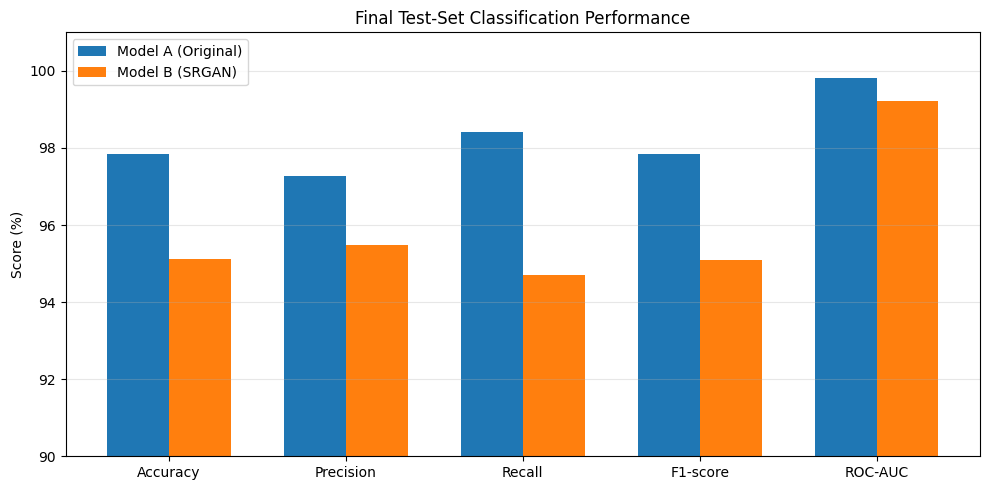

In [9]:
    # Load saved test-set evaluation results
comparison = pd.read_csv(
    PROJECT_ROOT / "results/evaluation/comparison.csv",
    index_col=0
)

comparison.index = ["Model A (Original)", "Model B (SRGAN)"]

# Display metrics as percentages
display((comparison * 100).round(2))

# Plot classification metrics
metrics = ["accuracy", "precision", "recall", "f1_score", "roc_auc"]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - width / 2,
    comparison.loc["Model A (Original)", metrics] * 100,
    width,
    label="Model A (Original)"
)

ax.bar(
    x + width / 2,
    comparison.loc["Model B (SRGAN)", metrics] * 100,
    width,
    label="Model B (SRGAN)"
)

ax.set_xticks(x)
ax.set_xticklabels(["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"])
ax.set_ylabel("Score (%)")
ax.set_ylim(90, 101)
ax.set_title("Final Test-Set Classification Performance")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Confusion Matrix Analysis

Confusion matrices show the number of correctly and incorrectly
classified cat and dog images for each model.

The diagonal entries represent correct predictions, while the
off-diagonal entries represent classification errors.

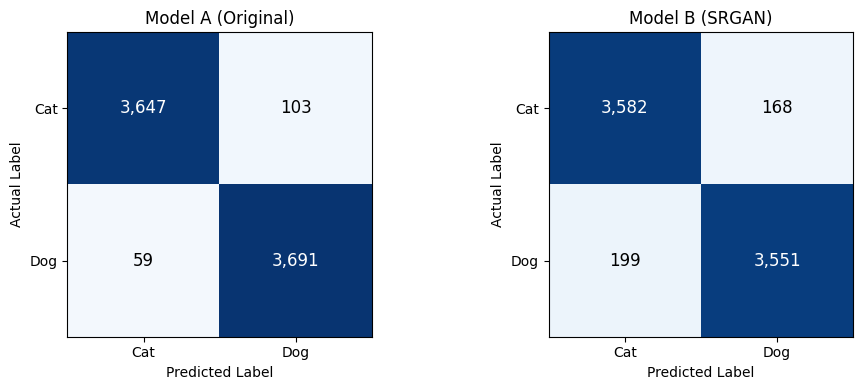

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

cm_a = pd.read_csv(
    PROJECT_ROOT / "results/evaluation/model_a_confusion_matrix.csv",
    index_col=0
).to_numpy(dtype=int)

cm_b = pd.read_csv(
    PROJECT_ROOT / "results/evaluation/model_b_confusion_matrix.csv",
    index_col=0
).to_numpy(dtype=int)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, cm, title in zip(
    axes,
    [cm_a, cm_b],
    ["Model A (Original)", "Model B (SRGAN)"]
):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=3750)

    ax.set_xticks([0, 1], ["Cat", "Dog"])
    ax.set_yticks([0, 1], ["Cat", "Dog"])

    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")
    ax.set_title(title)

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, f"{cm[i, j]:,}",
                ha="center",
                va="center",
                color="white" if cm[i, j] > 1875 else "black",
                fontsize=12
            )

plt.tight_layout()
plt.show()

## Discussion and Conclusion

In this project, I explored whether using SRGAN to improve low-resolution images could also improve cat-and-dog classification. To investigate this, I compared two models. Model A was trained on the original 128 × 128 images, while Model B was trained on images reconstructed by SRGAN from 32 × 32 inputs. Both models used MobileNetV2 for classification.

I trained the SRGAN for 150 epochs. By the final epoch, it achieved a validation PSNR of 25.31 dB and an SSIM of 0.7033. Looking at the image comparisons, the SRGAN outputs were noticeably clearer than the low-resolution inputs and looked quite similar to the original images.

However, the classification results were different from what I initially expected. Model A performed better than Model B across all evaluation metrics. Model A achieved 97.84% accuracy, while Model B reached 95.11%. The confusion matrices also showed a clear difference: Model A incorrectly classified 162 images, compared with 367 for Model B.

One possible explanation is that although SRGAN makes images look sharper, it cannot always recover the original details lost during downsampling. Some of these details may be important for distinguishing cats from dogs. This suggests that improving the visual quality of an image does not necessarily lead to better classification performance.

Overall, I was able to implement and evaluate both classification approaches and complete the SRGAN training pipeline. Although the SRGAN-based model did not outperform the original-image model, the results helped me understand the relationship between image reconstruction and classification. The main takeaway is that an image can look better visually without necessarily providing better information for a classification model.



### Model A: Classification Using Original Images

For Model A, I used MobileNetV2 as the backbone for binary cat-and-dog classification. Instead of training the entire network from scratch, I started with weights pretrained on ImageNet to take advantage of features the model had already learned.

The input images were resized to 128 × 128 pixels. During training, I applied random horizontal flipping, small rotations, and zooming to help the model learn from slightly different versions of the images.

I removed MobileNetV2's original classification layer and added global average pooling, a dropout layer with a rate of 0.3, and a dense layer with a sigmoid activation for binary classification.

Initially, I froze the MobileNetV2 backbone so that only the classification head could learn. I used the Adam optimizer with an initial learning rate of 0.0001 and binary cross-entropy as the loss function. Accuracy and AUC were used to monitor performance.

After training the classification head, I continued training and performed a separate fine-tuning stage to improve the model's performance.

### SRGAN Training Details

I trained the SRGAN in two stages. First, I pretrained the generator for 5 epochs using mean squared error (MSE) loss and the Adam optimizer with a learning rate of 0.0001. This helped the generator learn a basic reconstruction before starting adversarial training.

Next, I trained the generator and discriminator together for 150 epochs. Both networks used Adam with a learning rate of 0.0001. For the generator, I combined three losses: pixel loss (MSE), perceptual loss using VGG19 features, and adversarial loss. I used weights of 1, 0.006, and 0.001 for these losses, respectively. The discriminator used binary cross-entropy loss to distinguish real images from generated ones.

During training, I monitored the reconstruction quality using validation PSNR and SSIM. I also saved training checkpoints so I could resume training if needed, along with the best generator and final model weights.

### SRGAN: Image Super-Resolution

For the super-resolution part of the project, I implemented an SRGAN to reconstruct 128 × 128 images from 32 × 32 inputs. The SRGAN consists of two networks: a generator that creates high-resolution images and a discriminator that tries to distinguish generated images from real ones.

The generator starts with a convolutional layer followed by eight residual blocks. These blocks use convolutional layers, batch normalization, and PReLU activations to learn image features while preserving information through skip connections. After the residual blocks, two PixelShuffle upsampling blocks increase the image resolution from 32 × 32 to 64 × 64 and then to 128 × 128. The final convolutional layer uses a tanh activation to produce an RGB image.

The discriminator receives 128 × 128 images and uses several convolutional blocks with LeakyReLU activations. The number of filters increases from 64 to 512 as the image passes through the network. The final dense layer uses a sigmoid activation to predict whether an image is real or generated.

I first pretrained the generator and then trained the SRGAN adversarially for 150 epochs. During adversarial training, the generator learned to produce images that were closer to the original high-resolution images, while the discriminator learned to distinguish real images from generated ones.

I evaluated reconstruction quality using PSNR and SSIM. At the final training epoch, the validation PSNR reached 25.31 dB and SSIM reached 0.7033. I also compared original, low-resolution, and reconstructed images to visually examine the results.

### Model B: Classification Using SRGAN-Generated Images

For Model B, I used the same MobileNetV2 architecture as Model A, but trained it on images generated by the SRGAN instead of the original images. The SRGAN first reconstructed 128 × 128 images from 32 × 32 inputs, and these reconstructed images were then used for classification.

To keep the comparison fair, I initialized Model B with fresh ImageNet-pretrained weights rather than using the weights learned by Model A. I also kept the same classification head, data augmentation, and preprocessing approach.

I initially froze the MobileNetV2 backbone and trained the classification head for up to 10 epochs using a batch size of 32. I used Adam with a learning rate of 0.0001 and binary cross-entropy loss. During training, I monitored validation loss and used early stopping to reduce the risk of overfitting.

I saved the best model based on validation loss and recorded the training history. I also performed additional training and fine-tuning stages before evaluating Model B on the test dataset.

Finally, I compared Model B with Model A using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices to see whether the SRGAN-generated images improved classification performance.

### Classification Training Procedure

I trained both classification models in three stages to make the comparison consistent.

First, I froze the MobileNetV2 backbone and trained only the classification head. I then continued training the head using the saved model weights, allowing it more time to learn from the dataset. The initial and continued training stages covered 20 epochs in total for each model.

In the final stage, I fine-tuned part of the MobileNetV2 backbone while keeping some layers frozen. I reduced the learning rate from 0.0001 to 0.00001 to make smaller updates to the pretrained weights. Both models used a batch size of 32 throughout training.

I monitored validation performance and saved the best checkpoints during training. The training histories were also saved as CSV files, which I used to plot and compare the learning curves in this notebook.

This approach allowed me to compare the two models using the same architecture and overall training procedure, with the main difference being the type of input images: original images for Model A and SRGAN-reconstructed images for Model B.

Training Implementation
The models were trained on a GPU server using separate Python scripts. The code below shows the training implementation used for each stage. The saved training histories and evaluation results are presented in the following sections.

In [11]:
from pathlib import Path

training_scripts = [
    "src/pretrain_srgan.py",
    "src/train_srgan.py",
    "src/train_model_a.py",
    "src/continue_model_a.py",
    "src/finetune_model_a.py",
    "src/train_model_b.py",
    "src/continue_model_b.py",
    "src/finetune_model_b.py",
]

for script in training_scripts:
    path = PROJECT_ROOT / script
    print(f"{script}: {'Found' if path.exists() else 'MISSING'}")

src/pretrain_srgan.py: Found
src/train_srgan.py: Found
src/train_model_a.py: Found
src/continue_model_a.py: Found
src/finetune_model_a.py: Found
src/train_model_b.py: Found
src/continue_model_b.py: Found
src/finetune_model_b.py: Found


### Training Execution and Reproducibility

I ran the training experiments on a GPU server using TensorFlow and separate Python scripts. The SRGAN generator was pretrained first, followed by adversarial training. After training the SRGAN, I generated reconstructed images for Model B.

Both classification models were then trained in three stages: initial head training, continued head training, and fine-tuning.

The training scripts, saved histories, and evaluation outputs are organized in the project repository. The commands below show the order of the main training steps. These experiments have already been completed, so I use the saved results in this notebook instead of running the full training again.

In [14]:
training_commands = [
    "python src/pretrain_srgan.py",
    "python src/train_srgan.py --epochs 150",
    "python src/generate_model_b_data.py",
    "python src/train_model_a.py",
    "python src/continue_model_a.py",
    "python src/finetune_model_a.py",
    "python src/train_model_b.py",
    "python src/continue_model_b.py",
    "python src/finetune_model_b.py",
    "python src/evaluate_models.py",
]

print("Training and evaluation commands:\n")

for i, command in enumerate(training_commands, start=1):
    print(f"{i:2}. {command}")

Training and evaluation commands:

 1. python src/pretrain_srgan.py
 2. python src/train_srgan.py --epochs 150
 3. python src/generate_model_b_data.py
 4. python src/train_model_a.py
 5. python src/continue_model_a.py
 6. python src/finetune_model_a.py
 7. python src/train_model_b.py
 8. python src/continue_model_b.py
 9. python src/finetune_model_b.py
10. python src/evaluate_models.py


In [12]:
#Show evidence from the saved training histories
history_files = {
    "SRGAN pretraining": "results/srgan/pretrain_history.csv",
    "SRGAN adversarial training": "results/srgan/gan_history.csv",
    "Model A head": "results/model_a/head_history.csv",
    "Model A continued": "results/model_a/head_continued_history.csv",
    "Model A fine-tuning": "results/model_a/finetune_history.csv",
    "Model B head": "results/model_b/head_history.csv",
    "Model B continued": "results/model_b/head_continued_history.csv",
    "Model B fine-tuning": "results/model_b/finetune_history.csv",
}

records = []

for stage, relative_path in history_files.items():
    path = PROJECT_ROOT / relative_path
    history = pd.read_csv(path)

    records.append({
        "Training Stage": stage,
        "Completed Epochs": len(history),
        "History File": relative_path,
    })

pd.DataFrame(records)

,Training Stage,Completed Epochs,History File
0,SRGAN pretraining,5,results/srgan/pretrain_history.csv
1,SRGAN adversarial training,150,results/srgan/gan_history.csv
2,Model A head,10,results/model_a/head_history.csv
3,Model A continued,10,results/model_a/head_continued_history.csv
4,Model A fine-tuning,12,results/model_a/finetune_history.csv
5,Model B head,10,results/model_b/head_history.csv
6,Model B continued,10,results/model_b/head_continued_history.csv
7,Model B fine-tuning,14,results/model_b/finetune_history.csv


**Image Normalization and Data Augmentation**

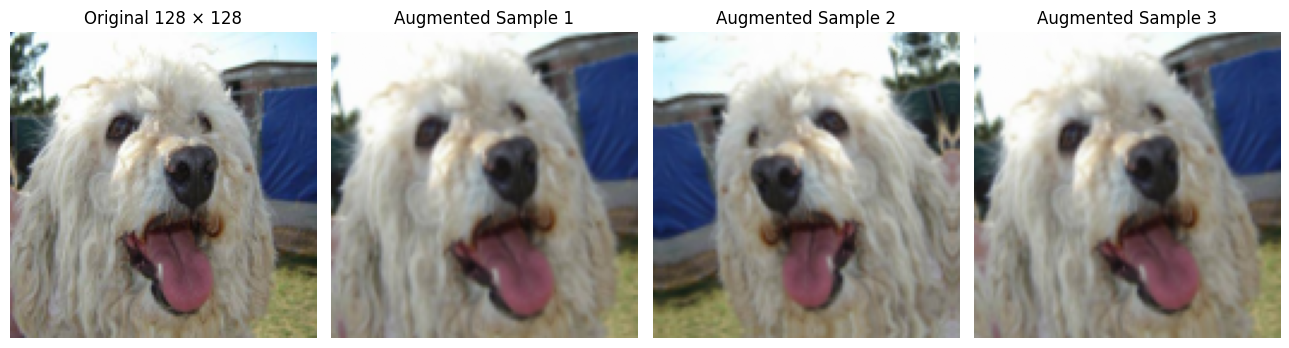

Original pixel range: 5.0 255.0
Normalized pixel range: -0.9607843 1.0


In [14]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Select a sample from the original test images
# Select a sample from the training dataset
train_df = pd.read_csv(PROJECT_ROOT / "data/splits/train_final.csv")
sample_path = PROJECT_ROOT / train_df.iloc[0]["filepath"]

image = Image.open(sample_path).convert("RGB").resize((128, 128))
image_array = np.asarray(image, dtype=np.float32)

# Normalize to [-1, 1]
normalized = image_array / 127.5 - 1.0

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
])

fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))

axes[0].imshow(image)
axes[0].set_title("Original 128 × 128")

for i in range(3):
    augmented = augmentation(
        tf.expand_dims(normalized, axis=0),
        training=True
    )[0].numpy()

    # Convert normalized pixels back to display range
    augmented = np.clip((augmented + 1) / 2, 0, 1)

    axes[i + 1].imshow(augmented)
    axes[i + 1].set_title(f"Augmented Sample {i + 1}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original pixel range:", image_array.min(), image_array.max())
print("Normalized pixel range:", normalized.min(), normalized.max())